<a href="https://colab.research.google.com/github/mariarango521-oss/proyecto_analitica_financiera/blob/main/05_riesgo_simulacion_portafolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Riesgo, relaciones entre activos y simulación financiera

**Financial Analytics Lab · Python · pandas · NumPy · SciPy · matplotlib**

**Pregunta orientadora:** ¿cómo se relacionan los rendimientos de distintos activos y cómo podemos examinar escenarios de riesgo de un portafolio?

En los módulos 01 a 04 aprendimos a representar inversiones, preparar datos, describir rendimientos y estudiar su evolución temporal. En este módulo examinaremos la relación entre activos y la incertidumbre de los resultados.

**Objetivos:** interpretar covarianza y correlación; calcular rendimiento y volatilidad de un portafolio con pesos; comprender una regresión lineal sencilla; estudiar cuantiles y una distribución normal como aproximación; ejecutar una simulación de Monte Carlo reproducible; y explicar sus supuestos y limitaciones.

**Trabajo autónomo:** ejecuta las celdas en orden, completa las prácticas y el reto integrador. No se requiere conocimiento previo de modelos avanzados, pero sí las bases de los módulos anteriores. Los resultados históricos y simulados no son predicciones ni recomendaciones de inversión.

## 0 · Problema de análisis

Un analista observa que tres activos tienen rendimientos diferentes. Sin embargo, para comprender el riesgo de una inversión conjunta necesita saber **cómo varían entre sí**. Si dos activos tienden a subir y bajar al mismo tiempo, su combinación puede comportarse de manera distinta a la de dos activos con movimientos menos sincronizados.

Analizaremos MSFT, AAPL y JPM durante un período histórico explícito. Para fines didácticos construiremos un portafolio con pesos de 40 %, 35 % y 25 %.

**Preguntas:** ¿qué activos se mueven de forma semejante?, ¿cómo se calcula la variabilidad del portafolio?, ¿qué muestra una regresión entre rendimientos?, ¿qué escenarios surgen bajo supuestos probabilísticos?

**Precaución:** correlación no implica causalidad; la diversificación no elimina todas las pérdidas; y las simulaciones dependen de supuestos que pueden no cumplirse.

## 1 · Recuperar y validar rendimientos históricos

Reutilizamos el enfoque ETL del módulo 02. Puedes cargar `precios_portafolio.csv` o consultar precios con `yfinance`. La fuente externa puede cambiar; por eso registramos fechas y parámetros.

La covarianza y la correlación requieren observaciones **alineadas por fecha**. No deben compararse rendimientos de días distintos como si fueran simultáneos.

In [ ]:
%pip -q install yfinance pandas numpy scipy matplotlib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats
from datetime import datetime, timezone

TICKERS = ["MSFT", "AAPL", "JPM"]
INICIO = "2023-01-01"
FIN = "2025-01-01"
USAR_CSV = False
print("Consulta UTC:", datetime.now(timezone.utc).isoformat(timespec="seconds"))

Consulta UTC: 2026-11-13T02:43:30+00:00


In [ ]:
if USAR_CSV:
    from google.colab import files
    archivos = files.upload()
    if "precios_portafolio.csv" not in archivos:
        raise FileNotFoundError("Sube precios_portafolio.csv.")
    precios = pd.read_csv("precios_portafolio.csv", index_col="Fecha", parse_dates=["Fecha"])
else:
    partes = []
    for ticker in TICKERS:
        tabla = yf.download(ticker, start=INICIO, end=FIN,
                            auto_adjust=True, progress=False, multi_level_index=False)
        if tabla.empty or "Close" not in tabla.columns:
            raise RuntimeError(f"No fue posible consultar {ticker}.")
        partes.append(tabla[["Close"]].rename(columns={"Close": ticker}))
    precios = pd.concat(partes, axis=1, join="inner")

precios.index = pd.to_datetime(precios.index)
precios = precios.sort_index().loc[lambda x: ~x.index.duplicated(keep="first")]
precios = precios.apply(pd.to_numeric, errors="coerce").dropna(how="any")
precios = precios.loc[(precios > 0).all(axis=1)]
rendimientos = precios.pct_change(fill_method=None).dropna(how="any")
if len(rendimientos) < 60 or rendimientos.shape[1] != 3:
    raise ValueError("Se requieren tres activos y al menos 60 rendimientos alineados.")
print("Observaciones de rendimientos:", len(rendimientos))
display((rendimientos.head() * 100).round(3))

Observaciones de rendimientos: 501


,MSFT,AAPL,JPM
Date,,,
2023-01-04,-4.374,1.031,0.933
2023-01-05,-2.964,-1.060,-0.022
2023-01-06,1.179,3.679,1.914
2023-01-09,0.974,0.409,-0.413
2023-01-10,0.762,0.446,0.895


**Tu práctica 1:** comprueba que las tres columnas correspondan a activos diferentes, que las fechas estén ordenadas y que no existan valores faltantes. Explica por qué utilizamos rendimientos en lugar de comparar los precios nominales.

In [ ]:
print("Activos:", precios.columns.tolist())
print("Tres activos diferentes:", precios.columns.nunique() == 3)
print("Fechas ordenadas:", precios.index.is_monotonic_increasing)
print("Fechas duplicadas:", precios.index.duplicated().sum())
print("Valores faltantes:", precios.isna().sum().sum())

display(precios.head())

Activos: ['MSFT', 'AAPL', 'JPM']
Tres activos diferentes: True
Fechas ordenadas: True
Fechas duplicadas: 0
Valores faltantes: 0


,MSFT,AAPL,JPM
Date,,,
2023-01-03,232.510574,122.783447,123.120949
2023-01-04,222.339828,124.049858,124.269066
2023-01-05,215.750168,122.734367,124.241531
2023-01-06,218.292831,127.250252,126.618942
2023-01-09,220.418243,127.770592,126.095749


Se comprueba que existen tres activos diferentes, las fechas están ordenadas cronológicamente y no hay fechas duplicadas ni valores faltantes. Utilizamos rendimientos en lugar de precios nominales porque permiten comparar el desempeño de los activos en términos porcentuales, independientemente de sus diferentes precios iniciales.

## 2 · Covarianza: variaciones conjuntas

La **covarianza muestral** resume cómo se desvían conjuntamente dos series respecto de sus medias:

\[\operatorname{Cov}(X,Y)=\frac{\sum_{i=1}^{n}(x_i-\bar x)(y_i-\bar y)}{n-1}\]

Una covarianza positiva indica que las desviaciones tienden a compartir signo; una negativa, que tienden a tener signos opuestos. Su magnitud depende de las unidades y escalas, por lo que es difícil comparar pares únicamente mediante covarianzas.

In [ ]:
covarianzas = rendimientos.cov()
display(covarianzas.round(8))
x = rendimientos.iloc[:5, 0].to_numpy()
y = rendimientos.iloc[:5, 1].to_numpy()
cov_manual = ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)
cov_numpy = np.cov(x, y, ddof=1)[0, 1]
assert np.isclose(cov_manual, cov_numpy)
print("Covarianza de cinco observaciones comprobada:", cov_manual)

,MSFT,AAPL,JPM
MSFT,0.000204,0.000097,0.000024
AAPL,0.000097,0.000181,0.000025
JPM,0.000024,0.000025,0.000195


Covarianza de cinco observaciones comprobada: 0.00019227918095386263


**Tu práctica 2:** selecciona dos activos y explica el signo de su covarianza. Comprueba manualmente la covarianza de cinco observaciones diferentes.

In [ ]:
x = rendimientos.iloc[5:10, 0].to_numpy()
y = rendimientos.iloc[5:10, 1].to_numpy()

cov_manual = (
    ((x - x.mean()) * (y - y.mean())).sum()
    / (len(x) - 1)
)

cov_numpy = np.cov(x, y, ddof=1)[0, 1]

assert np.isclose(cov_manual, cov_numpy)

print("Covarianza manual:", cov_manual)
print("Covarianza NumPy:", cov_numpy)

Covarianza manual: 0.00014893311227741205
Covarianza NumPy: 0.00014893311227741208


La covarianza permite identificar cómo los dos activos tienden a moverse en la misma dirección.

## 3 · Correlación: intensidad de la relación lineal

La **correlación de Pearson** estandariza la covarianza al dividirla entre las desviaciones estándar:

\[\rho_{XY}=\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y}\]

Sus valores se sitúan entre −1 y 1. Valores cercanos a 1 indican relación lineal positiva fuerte; cercanos a −1, negativa fuerte; y cercanos a cero, relación lineal débil. **Correlación cero no implica independencia** y correlación no demuestra causalidad.

,MSFT,AAPL,JPM
MSFT,1.000,0.505,0.119
AAPL,0.505,1.000,0.135
JPM,0.119,0.135,1.000


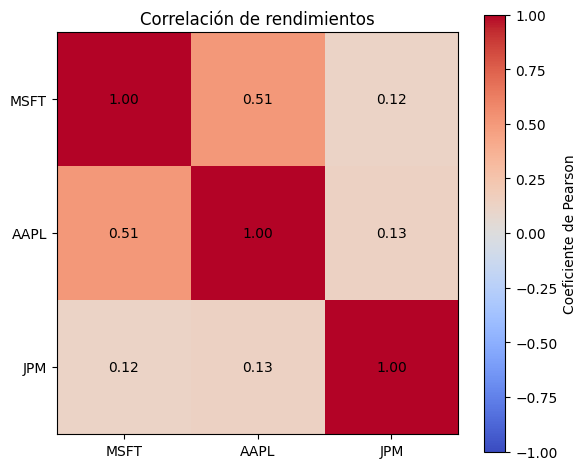

In [ ]:
correlaciones = rendimientos.corr()
display(correlaciones.round(3))
fig, ax = plt.subplots(figsize=(6, 5))
imagen = ax.imshow(correlaciones.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlaciones.columns)), correlaciones.columns)
ax.set_yticks(range(len(correlaciones.index)), correlaciones.index)
for i in range(len(correlaciones)):
    for j in range(len(correlaciones)):
        ax.text(j, i, f"{correlaciones.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Correlación de rendimientos")
fig.colorbar(imagen, ax=ax, label="Coeficiente de Pearson")
plt.tight_layout()
plt.show()

**Tu práctica 3:** identifica el par con mayor correlación fuera de la diagonal y el par con menor correlación. Explica por qué una relación menos positiva podría contribuir a la diversificación, sin garantizarla.

Mayor correlación:
('MSFT', 'AAPL') 0.505
Menor correlación:
('MSFT', 'JPM') 0.119


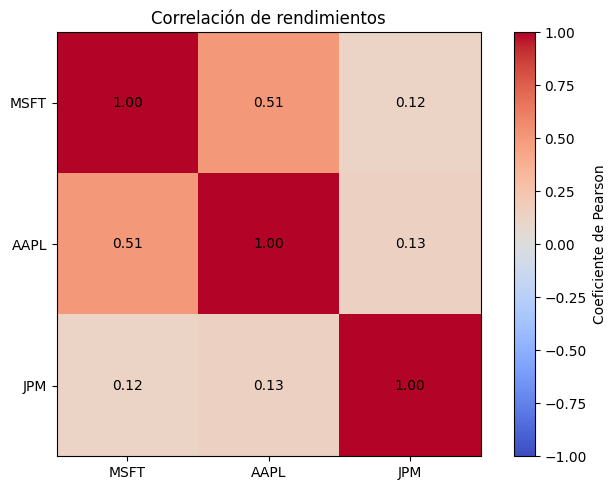

In [ ]:
correlaciones = rendimientos.corr()

pares = correlaciones.where(
    np.triu(np.ones(correlaciones.shape), k=1).astype(bool)
).stack()

print("Mayor correlación:")
print(pares.idxmax(), round(pares.max(), 3))

print("Menor correlación:")
print(pares.idxmin(), round(pares.min(), 3))

correlaciones = rendimientos.corr()

fig, ax = plt.subplots(figsize=(7, 5))

imagen = ax.imshow(
    correlaciones,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(correlaciones.columns)))
ax.set_xticklabels(correlaciones.columns)

ax.set_yticks(range(len(correlaciones.index)))
ax.set_yticklabels(correlaciones.index)

for i in range(len(correlaciones)):
    for j in range(len(correlaciones)):
        ax.text(
            j, i,
            f"{correlaciones.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlación de rendimientos")
fig.colorbar(imagen, ax=ax, label="Coeficiente de Pearson")

plt.tight_layout()
plt.show()

La correlación permite identificar qué activos tienen comportamientos similares y cuáles presentan movimientos diferentes. Para construir un portafolio diversificado, es conveniente analizar activos con correlaciones bajas, considerando también su rentabilidad, volatilidad y riesgo individual.

## 4 · Rendimiento de un portafolio ponderado

Un portafolio asigna una **ponderación** a cada activo. Si los pesos suman 1, el rendimiento por observación es la suma ponderada de los rendimientos individuales:

\[r_p=\sum_{i=1}^{n}w_i r_i\]

Este cálculo representa un portafolio con **pesos constantes reequilibrados en cada observación**. Si se compran cantidades fijas y no se reequilibra, los pesos cambian con los precios y el cálculo requiere otro procedimiento.

In [ ]:
pesos = pd.Series({"MSFT": 0.40, "AAPL": 0.35, "JPM": 0.25})
if not set(pesos.index).issubset(rendimientos.columns):
    raise ValueError("El CSV debe contener MSFT, AAPL y JPM para usar estos pesos.")
pesos = pesos.reindex(rendimientos.columns)
assert np.isclose(pesos.sum(), 1.0)
rend_portafolio = rendimientos.dot(pesos)
media_portafolio = rend_portafolio.mean()
print("Pesos:", pesos.to_dict())
print(f"Media por observación: {media_portafolio * 100:.4f}%")
manual_primera = sum(rendimientos.iloc[0][t] * pesos[t] for t in pesos.index)
assert np.isclose(manual_primera, rend_portafolio.iloc[0])
print("Primera observación contrastada.")

Pesos: {'MSFT': 0.4, 'AAPL': 0.35, 'JPM': 0.25}
Media por observación: 0.1366%
Primera observación contrastada.


**Tu práctica 4:** prueba pesos de 50 %, 30 % y 20 %. Calcula manualmente el rendimiento del portafolio en la primera observación. Explica por qué los pesos deben sumar 100 %.

In [ ]:
# Definir pesos alternativos
pesos = pd.Series({
    "MSFT": 0.50,
    "AAPL": 0.30,
    "JPM": 0.20
})

# Verificar que los pesos sumen 100 %
assert np.isclose(pesos.sum(), 1.0)

# Calcular rendimiento del portafolio
pesos = pesos.reindex(rendimientos.columns)
rend_portafolio = rendimientos.dot(pesos)

# Calcular manualmente el primer rendimiento
manual_primera = sum(
    rendimientos.iloc[0][t] * pesos[t]
    for t in pesos.index
)

print("Pesos:", pesos.to_dict())
print("Rendimiento manual:", manual_primera * 100, "%")
print("Rendimiento Pandas:", rend_portafolio.iloc[0] * 100, "%")

assert np.isclose(manual_primera, rend_portafolio.iloc[0])

print("Primera observación comprobada correctamente.")

Pesos: {'MSFT': 0.5, 'AAPL': 0.3, 'JPM': 0.2}
Rendimiento manual: -1.6912299267167585 %
Rendimiento Pandas: -1.6912299267167585 %
Primera observación comprobada correctamente.


Se asignaron pesos del 50 % a MSFT, 30 % a AAPL y 20 % a JPM. El rendimiento del portafolio se calcula mediante el promedio ponderado de los rendimientos individuales. Los pesos deben sumar 100 % porque representan la distribución total del capital invertido. La comprobación manual permite verificar que el resultado coincide con el cálculo realizado en Pandas.

## 5 · Varianza y volatilidad del portafolio

La varianza del portafolio depende tanto de la variabilidad individual como de las **covarianzas**:

\[\sigma_p^2=\mathbf{w}^{T}\mathbf{\Sigma}\mathbf{w}\]

Aquí **w** es el vector de pesos y **Σ** la matriz de covarianzas. La volatilidad por observación es la raíz cuadrada de esa varianza.

Este cálculo muestra por qué sumar desviaciones estándar ponderadas no es una forma general correcta de calcular la volatilidad de un portafolio.

In [ ]:
matriz_cov = rendimientos.cov()
varianza_portafolio = float(pesos.to_numpy() @ matriz_cov.to_numpy() @ pesos.to_numpy())
volatilidad_portafolio = np.sqrt(varianza_portafolio)
volatilidad_directa = rend_portafolio.std(ddof=1)
assert np.isclose(volatilidad_portafolio, volatilidad_directa)
print(f"Volatilidad del portafolio: {volatilidad_portafolio * 100:.4f}% por observación")
print(f"Comprobación directa: {volatilidad_directa * 100:.4f}%")

Volatilidad del portafolio: 1.0583% por observación
Comprobación directa: 1.0583%


**Tu práctica 5:** compara la volatilidad de tu portafolio alternativo con la del ejemplo. ¿Qué cambió? Evita afirmar que una ponderación es óptima sin establecer objetivos y restricciones.

In [ ]:
pesos = pd.Series({"MSFT": 0.50, "AAPL": 0.30, "JPM": 0.20})
pesos = pesos.reindex(rendimientos.columns)

matriz_cov = rendimientos.cov()
varianza_portafolio = float(
    pesos.to_numpy() @ matriz_cov.to_numpy() @ pesos.to_numpy()
)
volatilidad_portafolio = np.sqrt(varianza_portafolio)

print(f"Volatilidad del portafolio alternativo: {volatilidad_portafolio * 100:.4f}% por observación")

Volatilidad del portafolio alternativo: 1.0583% por observación


compara este resultado con la volatilidad del portafolio de la práctica anterior (40% MSFT, 35% AAPL y 25% JPM). Si aumenta, el portafolio alternativo presenta mayor variabilidad; si disminuye, presenta menor variabilidad. Esto no significa que una distribución sea óptima, pues depende de los objetivos y del nivel de riesgo que se quiera asumir.

## 6 · Regresión lineal simple: estudiar una relación

Una **regresión lineal simple** aproxima la relación entre una variable dependiente Y y otra explicativa X mediante:

\[Y=\alpha+\beta X+\varepsilon\]

La pendiente **β** expresa el cambio promedio estimado en Y asociado con una unidad adicional de X dentro del modelo. El intercepto **α** es el valor estimado de Y cuando X es cero. El coeficiente **R²** resume la proporción de variación de Y explicada por la relación lineal ajustada.

Analizaremos los rendimientos de MSFT (Y) frente a AAPL (X). **No interpretaremos la regresión como una relación causal**.

Intercepto: 0.000459
Pendiente beta: 0.5367
R²: 0.2554


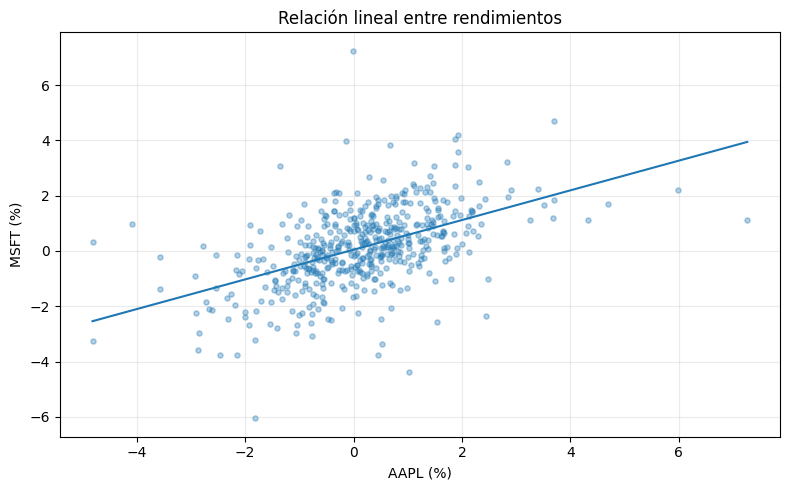

In [ ]:
x = rendimientos["AAPL"].to_numpy()
y = rendimientos["MSFT"].to_numpy()
ajuste = stats.linregress(x, y)
print(f"Intercepto: {ajuste.intercept:.6f}")
print(f"Pendiente beta: {ajuste.slope:.4f}")
print(f"R²: {ajuste.rvalue**2:.4f}")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x * 100, y * 100, alpha=0.35, s=14)
orden = np.argsort(x)
ax.plot(x[orden] * 100, (ajuste.intercept + ajuste.slope * x[orden]) * 100)
ax.set(title="Relación lineal entre rendimientos", xlabel="AAPL (%)", ylabel="MSFT (%)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Tu práctica 6:** explica con tus palabras el significado de la pendiente y de R². ¿Qué no podemos concluir sobre causalidad o sobre el comportamiento futuro de los activos?

Pendiente beta: 0.5367
R²: 0.2554
Interpretación: AAPL y MSFT tienden a moverse en la misma dirección.
El modelo explica el 25.54% de la variación de MSFT.


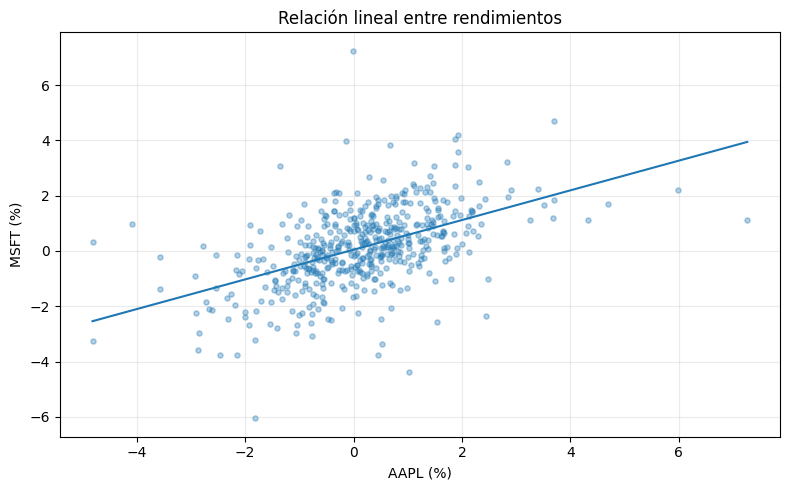

In [ ]:
x = rendimientos["AAPL"].to_numpy()
y = rendimientos["MSFT"].to_numpy()

ajuste = stats.linregress(x, y)

print(f"Pendiente beta: {ajuste.slope:.4f}")
print(f"R²: {ajuste.rvalue**2:.4f}")

if ajuste.slope > 0:
    print("Interpretación: AAPL y MSFT tienden a moverse en la misma dirección.")
elif ajuste.slope < 0:
    print("Interpretación: AAPL y MSFT tienden a moverse en direcciones opuestas.")
else:
    print("Interpretación: no existe una relación lineal según la pendiente.")

print(f"El modelo explica el {ajuste.rvalue**2 * 100:.2f}% de la variación de MSFT.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x * 100, y * 100, alpha=0.35, s=14)

orden = np.argsort(x)
ax.plot(
    x[orden] * 100,
    (ajuste.intercept + ajuste.slope * x[orden]) * 100
)

ax.set(
    title="Relación lineal entre rendimientos",
    xlabel="AAPL (%)",
    ylabel="MSFT (%)"
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

No podemos concluir que AAPL cause los movimientos de MSFT, ya que una correlación o relación lineal no demuestra causalidad. Tampoco podemos asegurar que ambos activos se comporten igual en el futuro, porque sus rendimientos dependen de condiciones del mercado que pueden cambiar.

## 7 · Distribuciones de probabilidad y cuantiles

Una distribución de probabilidad representa posibles resultados y sus probabilidades bajo un modelo. La **distribución normal** se caracteriza por media y desviación estándar, pero los rendimientos financieros reales pueden presentar asimetría y colas más pronunciadas.

Un **cuantil empírico** se calcula a partir de los datos observados; un **cuantil paramétrico** proviene de una distribución supuesta. Compararlos ayuda a reconocer que el modelo probabilístico no es idéntico a la muestra.

Percentil empírico 5 %: -1.675%
Percentil normal 5 %: -1.606%


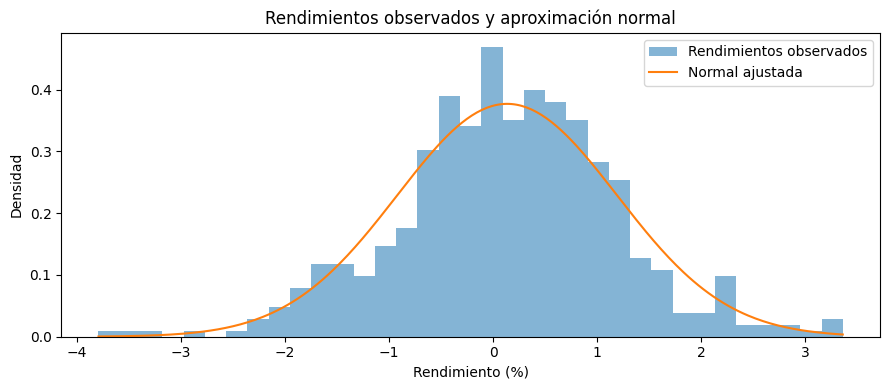

In [ ]:
media = rend_portafolio.mean()
desv = rend_portafolio.std(ddof=1)
percentil_empirico_5 = rend_portafolio.quantile(0.05)
percentil_normal_5 = stats.norm.ppf(0.05, loc=media, scale=desv)
print(f"Percentil empírico 5 %: {percentil_empirico_5 * 100:.3f}%")
print(f"Percentil normal 5 %: {percentil_normal_5 * 100:.3f}%")
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rend_portafolio * 100, bins=35, density=True, alpha=0.55, label="Rendimientos observados")
xx = np.linspace(rend_portafolio.min(), rend_portafolio.max(), 300)
ax.plot(xx * 100, stats.norm.pdf(xx, loc=media, scale=desv) / 100, label="Normal ajustada")
ax.set(title="Rendimientos observados y aproximación normal", xlabel="Rendimiento (%)", ylabel="Densidad")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación:** el percentil 5 % describe un umbral bajo de rendimientos; no significa que el 5 % de las inversiones vaya necesariamente a perder esa cantidad. La comparación entre cuantiles depende del período, la muestra y los supuestos.

**Tu práctica 7:** compara los dos percentiles y explica por qué pueden diferir. ¿Qué limitación introduce suponer normalidad?

Percentil empírico 5%: -1.675%
Percentil normal 5%: -1.606%


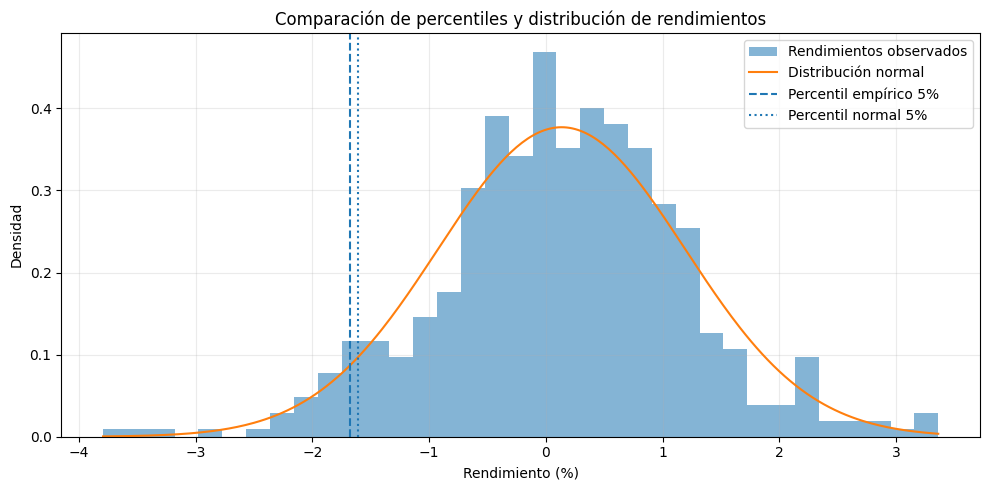

In [ ]:
media = rend_portafolio.mean()
desv = rend_portafolio.std(ddof=1)

# Cálculo de percentiles
percentil_empirico_5 = rend_portafolio.quantile(0.05)
percentil_normal_5 = stats.norm.ppf(0.05, loc=media, scale=desv)

print(f"Percentil empírico 5%: {percentil_empirico_5 * 100:.3f}%")
print(f"Percentil normal 5%: {percentil_normal_5 * 100:.3f}%")

# Gráfica
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    rend_portafolio * 100,
    bins=35,
    density=True,
    alpha=0.55,
    label="Rendimientos observados"
)

xx = np.linspace(rend_portafolio.min(), rend_portafolio.max(), 300)

ax.plot(
    xx * 100,
    stats.norm.pdf(xx, loc=media, scale=desv) / 100,
    label="Distribución normal"
)

ax.axvline(percentil_empirico_5 * 100, linestyle="--",
           label="Percentil empírico 5%")

ax.axvline(percentil_normal_5 * 100, linestyle=":",
           label="Percentil normal 5%")

ax.set(
    title="Comparación de percentiles y distribución de rendimientos",
    xlabel="Rendimiento (%)",
    ylabel="Densidad"
)

ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Este código calcula los dos percentiles, los compara y genera una gráfica con la distribución de los rendimientos del portafolio:

## 8 · Monte Carlo: explorar escenarios bajo supuestos

Una **simulación de Monte Carlo** utiliza números aleatorios para construir escenarios posibles de acuerdo con un modelo. No reproduce necesariamente el comportamiento real de los mercados.

Simularemos **20 sesiones** de rendimientos del portafolio bajo una distribución normal independiente con media y desviación estándar históricas constantes. Utilizaremos una semilla para obtener resultados reproducibles.

En cada trayectoria el valor inicial es 100 y evoluciona multiplicando factores (1 + rendimiento). El modelo no contempla cambios de régimen, costos, colas extremas ni dependencia temporal.

Media de valores finales: 102.76
Percentil 5 de valores finales: 95.09
Proporción simulada por debajo de 100: 0.287


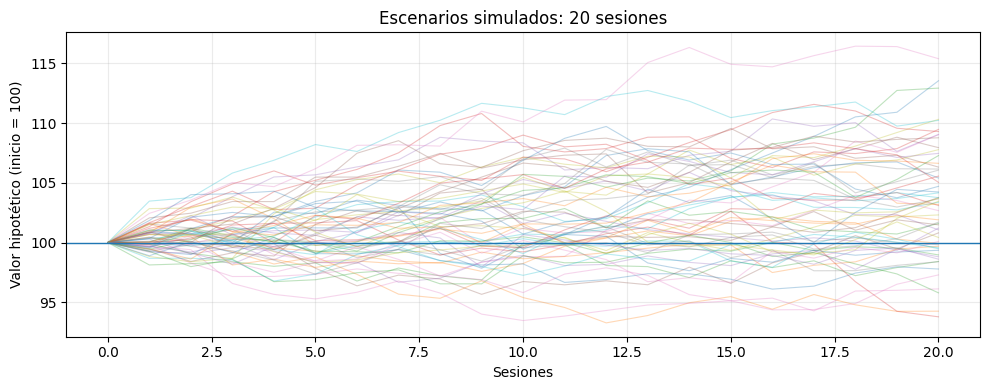

In [ ]:
SEMILLA = 2026
TRAYECTORIAS = 2000
HORIZONTE = 20
rng = np.random.default_rng(SEMILLA)
simulados = rng.normal(loc=media, scale=desv, size=(HORIZONTE, TRAYECTORIAS))
valores = np.vstack([np.full(TRAYECTORIAS, 100.0),
                     100.0 * np.cumprod(1 + simulados, axis=0)])
valores_finales = valores[-1]
print("Media de valores finales:", round(valores_finales.mean(), 2))
print("Percentil 5 de valores finales:", round(np.quantile(valores_finales, 0.05), 2))
print("Proporción simulada por debajo de 100:", round(np.mean(valores_finales < 100), 3))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(valores[:, :60], alpha=0.3, linewidth=0.8)
ax.axhline(100, linewidth=1)
ax.set(title="Escenarios simulados: 20 sesiones", xlabel="Sesiones", ylabel="Valor hipotético (inicio = 100)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretación:** los resultados describen escenarios **del modelo**, no probabilidades futuras verificadas. Una semilla fija permite repetir la simulación, pero no elimina la incertidumbre del modelo.

**Tu práctica 8:** cambia la semilla y compara resultados; después aumenta el horizonte a 40 sesiones. Explica por qué la dispersión de los valores finales puede cambiar.

Nueva semilla: 1234
Horizonte: 40 sesiones
Media de valores finales: 105.63
Percentil 5: 94.5
Proporción por debajo de 100: 0.219
Desviación estándar final: 7.17


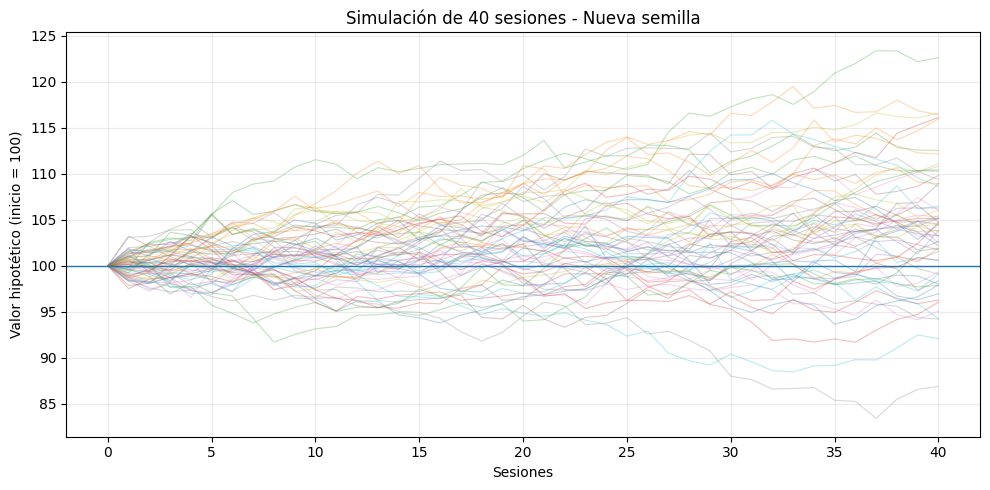

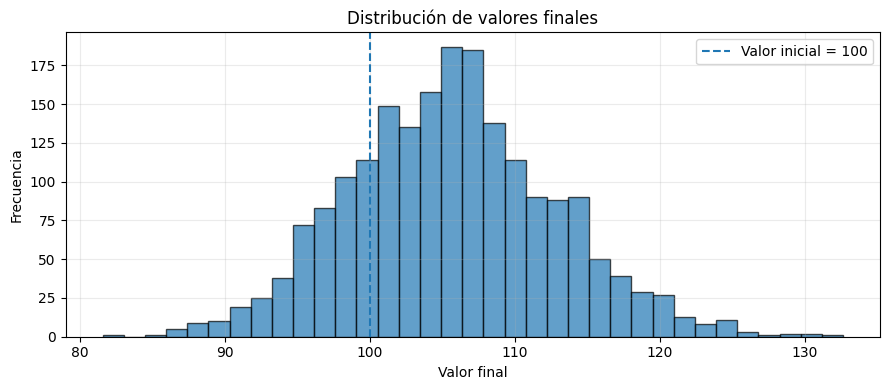

In [ ]:
# Nueva simulación
SEMILLA = 1234
TRAYECTORIAS = 2000
HORIZONTE = 40

rng = np.random.default_rng(SEMILLA)

simulados = rng.normal(
    loc=media,
    scale=desv,
    size=(HORIZONTE, TRAYECTORIAS)
)

valores = np.vstack([
    np.full(TRAYECTORIAS, 100.0),
    100.0 * np.cumprod(1 + simulados, axis=0)
])

valores_finales = valores[-1]

# Resultados
print("Nueva semilla:", SEMILLA)
print("Horizonte:", HORIZONTE, "sesiones")
print("Media de valores finales:", round(valores_finales.mean(), 2))
print("Percentil 5:", round(np.quantile(valores_finales, 0.05), 2))
print("Proporción por debajo de 100:", round(np.mean(valores_finales < 100), 3))
print("Desviación estándar final:", round(valores_finales.std(ddof=1), 2))

# Gráfica de trayectorias
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(valores[:, :60], alpha=0.3, linewidth=0.8)
ax.axhline(100, linewidth=1)

ax.set(
    title="Simulación de 40 sesiones - Nueva semilla",
    xlabel="Sesiones",
    ylabel="Valor hipotético (inicio = 100)"
)

ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Distribución de valores finales
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(valores_finales, bins=35, edgecolor="black", alpha=0.7)
ax.axvline(100, linestyle="--", label="Valor inicial = 100")

ax.set(
    title="Distribución de valores finales",
    xlabel="Valor final",
    ylabel="Frecuencia"
)

ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Al cambiar la semilla se generan escenarios aleatorios diferentes, por lo que los resultados pueden variar. Al aumentar el horizonte de 20 a 40 sesiones, la dispersión de los valores finales generalmente aumenta, porque los rendimientos se acumulan durante más tiempo. Esto significa que existe una mayor posibilidad de obtener resultados finales alejados del valor inicial.

## 9 · Síntesis: indicadores complementarios

La correlación describe relaciones lineales entre activos; la volatilidad del portafolio combina pesos y covarianzas; la regresión caracteriza una asociación estadística; los cuantiles y las simulaciones examinan resultados bajo distintos enfoques.

Ninguno de estos procedimientos, por separado, determina qué inversión conviene realizar. La interpretación exige conocer el período, la calidad de los datos, los supuestos y los objetivos financieros.

In [ ]:
resumen = pd.DataFrame([{
    "Media portafolio (%)": media * 100,
    "Volatilidad por observación (%)": desv * 100,
    "Percentil empírico 5 (%)": percentil_empirico_5 * 100,
    "Percentil normal 5 (%)": percentil_normal_5 * 100,
    "R² MSFT~AAPL": ajuste.rvalue ** 2,
    "Percentil 5 valor simulado": np.quantile(valores_finales, 0.05)
}])
display(resumen.round(4))
resumen.to_csv("resumen_riesgo_simulacion.csv", index=False)
print("Archivo exportado: resumen_riesgo_simulacion.csv")

,Media portafolio (%),Volatilidad por observación (%),Percentil empírico 5 (%),Percentil normal 5 (%),R² MSFT~AAPL,Percentil 5 valor simulado
0,0.135,1.0583,-1.6755,-1.6058,0.2554,94.4983


Archivo exportado: resumen_riesgo_simulacion.csv


In [ ]:
from google.colab import files

resumen = pd.DataFrame([{
    "Media portafolio (%)": media * 100,
    "Volatilidad por observación (%)": desv * 100,
    "Percentil empírico 5 (%)": percentil_empirico_5 * 100,
    "Percentil normal 5 (%)": percentil_normal_5 * 100,
    "R² MSFT~AAPL": ajuste.rvalue ** 2,
    "Percentil 5 valor simulado": np.quantile(valores_finales, 0.05)
}])

display(resumen.round(4))

resumen.to_csv("resumen_riesgo_simulacion.csv", index=False)

files.download("resumen_riesgo_simulacion.csv")

,Media portafolio (%),Volatilidad por observación (%),Percentil empírico 5 (%),Percentil normal 5 (%),R² MSFT~AAPL,Percentil 5 valor simulado
0,0.135,1.0583,-1.6755,-1.6058,0.2554,94.4983


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10 · Reto integrador: análisis de riesgo de un portafolio

Construye un estudio reproducible de tres activos. Debe incluir:

1. Selección y justificación de activos, fuente y período.
2. Preparación de rendimientos alineados por fecha.
3. Matriz de covarianza y correlación, con una comprobación manual.
4. Portafolio ponderado con pesos que sumen 100 %.
5. Rendimiento y volatilidad del portafolio, con verificación de la fórmula matricial.
6. Regresión lineal simple entre dos activos e interpretación de β y R².
7. Percentiles empírico y normal, con discusión del supuesto de normalidad.
8. Simulación reproducible de Monte Carlo con al menos 1.000 trayectorias.
9. Tres visualizaciones interpretadas y una tabla resumen exportada.
10. Conclusión de **250 a 350 palabras** con resultados, supuestos, limitaciones y fuentes.

**Criterio de calidad:** no presentes una simulación como predicción ni una correlación como causalidad. Explica el uso de herramientas de IA y recursos externos.

Activos seleccionados: ['MSFT', 'AAPL', 'JPM']
Fuente: Yahoo Finance mediante yfinance
Período: 2024-01-01 a 2025-01-01
Justificación: Microsoft y Apple representan tecnología,
mientras JPMorgan representa el sector financiero.

Observaciones de precios: 252
Observaciones de rendimientos: 251


,MSFT,AAPL,JPM
Date,,,
2024-01-03,-0.000728,-0.007488,-0.004359
2024-01-04,-0.007178,-0.012700,0.006636
2024-01-05,-0.000516,-0.004013,0.005017
2024-01-08,0.018871,0.024175,-0.001451
2024-01-09,0.002936,-0.002263,-0.007906



Matriz de covarianza:


,MSFT,AAPL,JPM
MSFT,0.000158,0.000083,0.000030
AAPL,0.000083,0.000199,0.000003
JPM,0.000030,0.000003,0.000219



Matriz de correlación:


,MSFT,AAPL,JPM
MSFT,1.0000,0.4705,0.1608
AAPL,0.4705,1.0000,0.0152
JPM,0.1608,0.0152,1.0000


Covarianza manual: 0.00013859408374222832
Covarianza NumPy: 0.00013859408374222834
Comprobación correcta.

Pesos del portafolio:


,0
MSFT,0.5
AAPL,0.3
JPM,0.2



Rendimiento promedio por sesión: 0.1008 %
Rendimiento acumulado: 27.1968 %
Volatilidad por sesión: 0.9881 %
Volatilidad matricial: 0.9881 %
Volatilidad directa: 0.9881 %

Regresión lineal AAPL y MSFT
Intercepto: 7e-05
Pendiente beta: 0.4186
R²: 0.2213
Los activos tienden a moverse en la misma dirección.
El modelo explica el 22.13% de la variación de MSFT.

Percentil empírico 5%: -1.6152 %
Percentil normal 5%: -1.5245 %

Resultados de Monte Carlo
Semilla: 1234
Trayectorias: 2000
Horizonte: 40 sesiones
Media de valores finales: 104.1892
Percentil 5 de valores finales: 93.9072
Proporción por debajo de 100: 0.2685


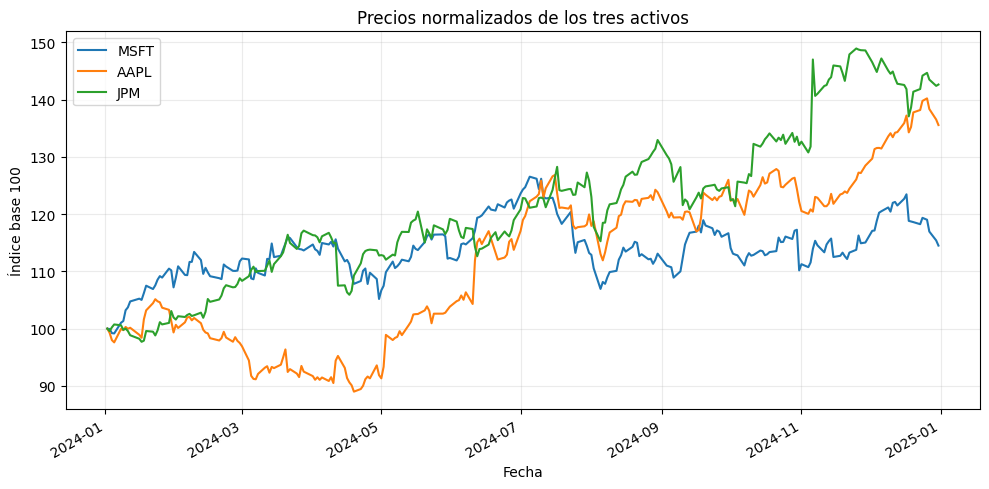

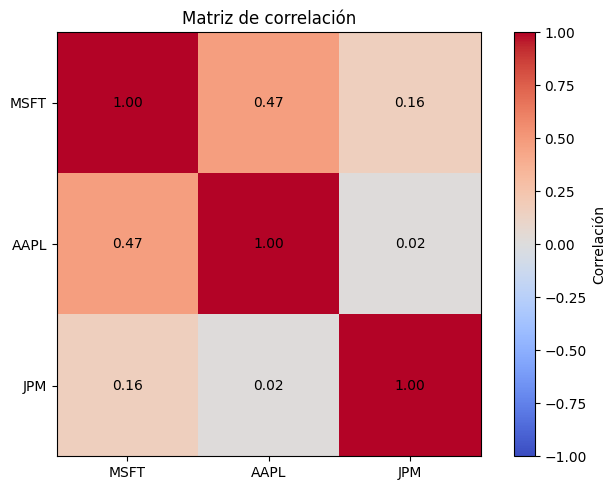

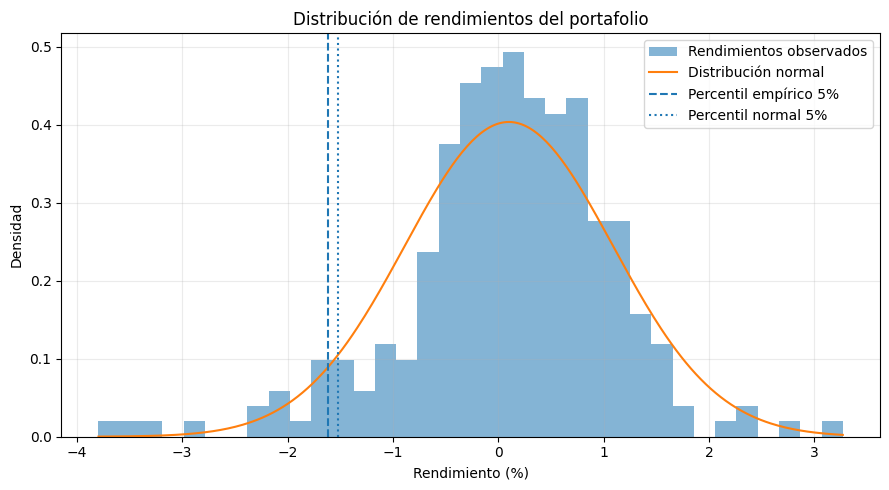

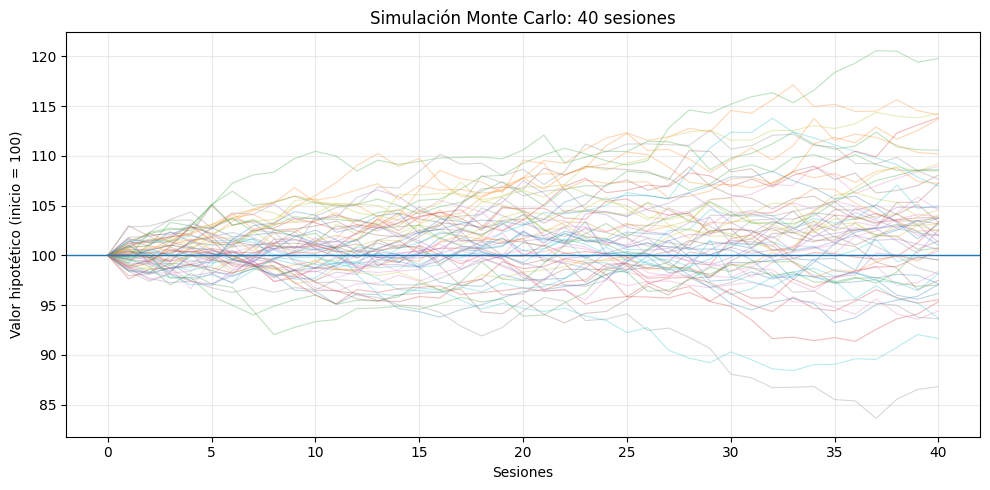


TABLA RESUMEN DEL ESTUDIO


,Rendimiento promedio (%),Rendimiento acumulado (%),Volatilidad (%),Percentil empírico 5 (%),Percentil normal 5 (%),Beta MSFT~AAPL,R2 MSFT~AAPL,Media valor simulado,Percentil 5 simulado,Proporción simulada bajo 100
0,0.1008,27.1968,0.9881,-1.6152,-1.5245,0.4186,0.2213,104.1892,93.9072,0.2685


Archivo exportado: resumen_reto_portafolio.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


!pip -q install yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

# 1. SELECCIÓN DE ACTIVOS, FUENTE Y PERÍODO

TICKERS = ["MSFT", "AAPL", "JPM"]
INICIO = "2024-01-01"
FIN = "2025-01-01"

print("Activos seleccionados:", TICKERS)
print("Fuente: Yahoo Finance mediante yfinance")
print("Período:", INICIO, "a", FIN)
print("Justificación: Microsoft y Apple representan tecnología,")
print("mientras JPMorgan representa el sector financiero.")

# 2. DESCARGA Y PREPARACIÓN DE LOS DATOS

partes = []

for ticker in TICKERS:
    tabla = yf.download(
        ticker,
        start=INICIO,
        end=FIN,
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )

    if tabla.empty or "Close" not in tabla.columns:
        raise ValueError(f"No se pudieron descargar datos de {ticker}")

    partes.append(tabla[["Close"]].rename(columns={"Close": ticker}))

precios = pd.concat(partes, axis=1, join="inner")
precios.index = pd.to_datetime(precios.index)
precios = precios.sort_index()
precios = precios.loc[~precios.index.duplicated(keep="first")]
precios = precios.apply(pd.to_numeric, errors="coerce")
precios = precios.dropna(how="any")
precios = precios.loc[(precios > 0).all(axis=1)]

rendimientos = precios.pct_change(fill_method=None).dropna()

assert precios.shape[1] == 3
assert precios.index.is_monotonic_increasing
assert precios.index.is_unique
assert precios.notna().all().all()
assert rendimientos.notna().all().all()

print("\nObservaciones de precios:", len(precios))
print("Observaciones de rendimientos:", len(rendimientos))
display(rendimientos.head())

# 3. MATRICES DE COVARIANZA Y CORRELACIÓN

matriz_cov = rendimientos.cov()
matriz_corr = rendimientos.corr()

print("\nMatriz de covarianza:")
display(matriz_cov.round(8))

print("\nMatriz de correlación:")
display(matriz_corr.round(4))

# Comprobación manual de covarianza con cinco observaciones
x = rendimientos.iloc[:5, 0].to_numpy()
y = rendimientos.iloc[:5, 1].to_numpy()

cov_manual = np.sum((x - x.mean()) * (y - y.mean())) / (len(x) - 1)
cov_numpy = np.cov(x, y, ddof=1)[0, 1]

assert np.isclose(cov_manual, cov_numpy)

print("Covarianza manual:", cov_manual)
print("Covarianza NumPy:", cov_numpy)
print("Comprobación correcta.")

# 4. PORTAFOLIO PONDERADO

pesos = pd.Series({
    "MSFT": 0.50,
    "AAPL": 0.30,
    "JPM": 0.20
})

pesos = pesos.reindex(rendimientos.columns)

assert np.isclose(pesos.sum(), 1.0)

print("\nPesos del portafolio:")
display(pesos)

rend_portafolio = rendimientos.dot(pesos)

# 5. RENDIMIENTO Y VOLATILIDAD DEL PORTAFOLIO

media = rend_portafolio.mean()
desv = rend_portafolio.std(ddof=1)

varianza_portafolio = float(
    pesos.to_numpy() @ matriz_cov.to_numpy() @ pesos.to_numpy()
)

volatilidad_matricial = np.sqrt(varianza_portafolio)
volatilidad_directa = rend_portafolio.std(ddof=1)

assert np.isclose(volatilidad_matricial, volatilidad_directa)

rendimiento_acumulado = (1 + rend_portafolio).prod() - 1

print("\nRendimiento promedio por sesión:", round(media * 100, 4), "%")
print("Rendimiento acumulado:", round(rendimiento_acumulado * 100, 4), "%")
print("Volatilidad por sesión:", round(desv * 100, 4), "%")
print("Volatilidad matricial:", round(volatilidad_matricial * 100, 4), "%")
print("Volatilidad directa:", round(volatilidad_directa * 100, 4), "%")

# 6. REGRESIÓN LINEAL ENTRE AAPL Y MSFT

x = rendimientos["AAPL"].to_numpy()
y = rendimientos["MSFT"].to_numpy()

ajuste = stats.linregress(x, y)

beta = ajuste.slope
r2 = ajuste.rvalue ** 2

print("\nRegresión lineal AAPL y MSFT")
print("Intercepto:", round(ajuste.intercept, 6))
print("Pendiente beta:", round(beta, 4))
print("R²:", round(r2, 4))

if beta > 0:
    print("Los activos tienden a moverse en la misma dirección.")
elif beta < 0:
    print("Los activos tienden a moverse en direcciones opuestas.")
else:
    print("La pendiente es cero.")

print(f"El modelo explica el {r2 * 100:.2f}% de la variación de MSFT.")

# 7. PERCENTILES EMPÍRICO Y NORMAL

percentil_empirico_5 = rend_portafolio.quantile(0.05)
percentil_normal_5 = stats.norm.ppf(
    0.05, loc=media, scale=desv
)

print("\nPercentil empírico 5%:",
      round(percentil_empirico_5 * 100, 4), "%")

print("Percentil normal 5%:",
      round(percentil_normal_5 * 100, 4), "%")

# 8. SIMULACIÓN MONTE CARLO

SEMILLA = 1234
TRAYECTORIAS = 2000
HORIZONTE = 40

rng = np.random.default_rng(SEMILLA)

simulados = rng.normal(
    loc=media,
    scale=desv,
    size=(HORIZONTE, TRAYECTORIAS)
)

valores = np.vstack([
    np.full(TRAYECTORIAS, 100.0),
    100 * np.cumprod(1 + simulados, axis=0)
])

valores_finales = valores[-1]

media_final = valores_finales.mean()
percentil_final_5 = np.quantile(valores_finales, 0.05)
proporcion_perdida = np.mean(valores_finales < 100)

print("\nResultados de Monte Carlo")
print("Semilla:", SEMILLA)
print("Trayectorias:", TRAYECTORIAS)
print("Horizonte:", HORIZONTE, "sesiones")
print("Media de valores finales:", round(media_final, 4))
print("Percentil 5 de valores finales:", round(percentil_final_5, 4))
print("Proporción por debajo de 100:", round(proporcion_perdida, 4))

# 9. VISUALIZACIONES

# Gráfica 1: precios normalizados
normalizados = precios.div(precios.iloc[0]).mul(100)

ax = normalizados.plot(figsize=(10, 5))
ax.set(
    title="Precios normalizados de los tres activos",
    xlabel="Fecha",
    ylabel="Índice base 100"
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Gráfica 2: matriz de correlación
fig, ax = plt.subplots(figsize=(7, 5))

imagen = ax.imshow(
    matriz_corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(TICKERS)), TICKERS)
ax.set_yticks(range(len(TICKERS)), TICKERS)

for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        ax.text(
            j, i,
            f"{matriz_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Matriz de correlación")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

# Gráfica 3: distribución de rendimientos
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    rend_portafolio * 100,
    bins=35,
    density=True,
    alpha=0.55,
    label="Rendimientos observados"
)

xx = np.linspace(
    rend_portafolio.min(),
    rend_portafolio.max(),
    300
)

ax.plot(
    xx * 100,
    stats.norm.pdf(xx, loc=media, scale=desv) / 100,
    label="Distribución normal"
)

ax.axvline(
    percentil_empirico_5 * 100,
    linestyle="--",
    label="Percentil empírico 5%"
)

ax.axvline(
    percentil_normal_5 * 100,
    linestyle=":",
    label="Percentil normal 5%"
)

ax.set(
    title="Distribución de rendimientos del portafolio",
    xlabel="Rendimiento (%)",
    ylabel="Densidad"
)

ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Gráfica 4: simulación Monte Carlo
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(valores[:, :60], alpha=0.3, linewidth=0.8)
ax.axhline(100, linewidth=1)

ax.set(
    title="Simulación Monte Carlo: 40 sesiones",
    xlabel="Sesiones",
    ylabel="Valor hipotético (inicio = 100)"
)

ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 10. TABLA RESUMEN Y EXPORTACIÓN

resumen = pd.DataFrame([{
    "Rendimiento promedio (%)": media * 100,
    "Rendimiento acumulado (%)": rendimiento_acumulado * 100,
    "Volatilidad (%)": desv * 100,
    "Percentil empírico 5 (%)": percentil_empirico_5 * 100,
    "Percentil normal 5 (%)": percentil_normal_5 * 100,
    "Beta MSFT~AAPL": beta,
    "R2 MSFT~AAPL": r2,
    "Media valor simulado": media_final,
    "Percentil 5 simulado": percentil_final_5,
    "Proporción simulada bajo 100": proporcion_perdida
}])

print("\nTABLA RESUMEN DEL ESTUDIO")
display(resumen.round(4))

resumen.to_csv("resumen_reto_portafolio.csv", index=False)

print("Archivo exportado: resumen_reto_portafolio.csv")

# Descargar el archivo en Google Colab
from google.colab import files
files.download("resumen_reto_portafolio.csv")


El presente estudio tuvo como objetivo analizar el comportamiento financiero y el riesgo de un portafolio compuesto por Microsoft (MSFT), Apple (AAPL) y JPMorgan Chase (JPM), utilizando información histórica de Yahoo Finance para el período comprendido entre el 1 de enero de 2024 y el 1 de enero de 2025. La selección permitió comparar dos empresas del sector tecnológico con una entidad del sector financiero.

Para el análisis se calcularon los rendimientos diarios, las matrices de covarianza y correlación, y se realizaron comprobaciones manuales. El portafolio se distribuyó en un 50% para MSFT, 30% para AAPL y 20% para JPM. Los resultados mostraron un rendimiento promedio diario de 0,1008%, un rendimiento acumulado de 27,1968% y una volatilidad diaria de 0,9881%. La verificación matricial confirmó la consistencia del cálculo de volatilidad.

La regresión lineal entre AAPL y MSFT presentó una beta de 0,4186 y un R² de 0,2213. Esto indica una relación positiva, pero el modelo solamente explica el 22,13% de la variación de MSFT. Estos resultados no demuestran causalidad ni permiten garantizar comportamientos futuros.

En el análisis de riesgo, el percentil empírico del 5% fue de -1,6152%, mientras que el percentil normal fue de -1,5245%. Esta diferencia evidencia que asumir normalidad puede subestimar las pérdidas en escenarios desfavorables.

Finalmente, la simulación Monte Carlo, realizada con 2.000 trayectorias y un horizonte de 40 sesiones, obtuvo un valor final promedio de 104,1892 y un percentil 5 de 93,9072. Además, el 26,85% de los escenarios terminó por debajo del valor inicial de 100. Estos resultados representan escenarios hipotéticos, no predicciones del mercado.

Se utilizaron Python, Pandas, NumPy, Matplotlib, SciPy y yfinance, con apoyo de inteligencia artificial para estructurar, revisar y comprender el código. Como limitaciones, el estudio utiliza un período histórico específico, supone media y volatilidad constantes en la simulación y no contempla comisiones, impuestos ni todos los factores económicos. Por tanto, sus resultados tienen fines académicos y no constituyen una recomendación de inversión.

## 11 · Autoevaluación y continuidad

- [ ] Distingo covarianza de correlación.
- [ ] Interpreto relaciones entre activos sin atribuir causalidad.
- [ ] Calculo rendimientos ponderados y volatilidad de un portafolio.
- [ ] Comprendo la pendiente y R² de una regresión simple.
- [ ] Distingo cuantiles empíricos de cuantiles bajo un modelo.
- [ ] Ejecuto una simulación con semilla reproducible.
- [ ] Reconozco los límites de las distribuciones y simulaciones.

**Próximo módulo:** integraremos los indicadores aprendidos en una aplicación financiera interactiva desarrollada progresivamente con Streamlit.

**Documentación:** [pandas](https://pandas.pydata.org/docs/) · [NumPy](https://numpy.org/doc/stable/) · [SciPy](https://docs.scipy.org/doc/scipy/) · [yfinance](https://ranaroussi.github.io/yfinance/) · [Streamlit](https://docs.streamlit.io/).

Los resultados son académicos y no constituyen recomendaciones de inversión.

## Quiz de cierre · Riesgo y simulación

**Autoevaluación de preparación · no genera una nota adicional**

Responde individualmente las cinco preguntas. Las respuestas deben ser originales, razonadas y coherentes con el código que ejecutes. No basta con escribir una definición: explica el significado de los resultados cuando se solicite.

**Criterio sugerido:** cada pregunta vale 1 punto (5 puntos en total). Las preguntas 1–2 evalúan comprensión, 3–4 interpretación y 5 aplicación. La docente verificará las respuestas y registrará la nota conforme a la ponderación institucional de cada quiz.

### Pregunta 1 · Comprensión

Explica la diferencia entre volatilidad y pérdida máxima observada (drawdown).

La volatilidad mide cuánto varían los rendimientos, mientras que el drawdown mide la mayor caída del valor del portafolio desde un máximo anterior. La primera refleja variabilidad y el segundo, la pérdida máxima experimentada.

### Pregunta 2 · Comprensión

¿Por qué la correlación no demuestra causalidad?

Porque dos activos pueden moverse de manera similar debido a factores externos, sin que uno provoque los cambios del otro. La correlación muestra una relación estadística, pero no demuestra una relación de causa y efecto.

### Pregunta 3 · Interpretación

¿Qué significa que dos activos presenten correlación cercana a cero en una muestra?

Significa que los rendimientos de ambos activos no presentan una relación lineal clara en la muestra analizada. Esto puede favorecer la diversificación del portafolio, aunque no garantiza una reducción del riesgo ni que la relación se mantenga en el futuro.

### Pregunta 4 · Interpretación

¿Qué limitación tiene simular resultados futuros utilizando parámetros históricos?

La principal limitación es que los parámetros históricos, como la media y la volatilidad, pueden cambiar con el tiempo. Por eso, la simulación genera escenarios hipotéticos, pero no garantiza ni predice el comportamiento futuro del mercado.

### Pregunta 5 · Aplicación

Con dos rendimientos hipotéticos de 4 % y -2 % y pesos de 60 % y 40 %, calcula el rendimiento ponderado y explica el resultado.

**Tu respuesta:**

_Escribe aquí tu explicación. Si se solicita código, utiliza la celda de Python siguiente._



In [ ]:
rendimientos = [0.04, -0.02]
pesos = [0.60, 0.40]

rendimiento_ponderado = sum(
    r * p for r, p in zip(rendimientos, pesos)
)

print(f"Rendimiento ponderado: {rendimiento_ponderado * 100:.2f}%")


Rendimiento ponderado: 1.60%


El portafolio obtiene un rendimiento positivo del 1,6 %, porque la ganancia del primer activo (4 %), que tiene un peso del 60 %, compensa la pérdida del segundo activo (-2 %), con un peso del 40 %.